<a href="https://colab.research.google.com/github/Tinnnn-vn/tiny-gpt-diffusion/blob/main/Diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Thiết bị đang dùng: cpu
Shape của images: torch.Size([128, 1, 28, 28])
Shape của labels: torch.Size([128])
Giá trị nhỏ nhất: -1.0
Giá trị lớn nhất: 1.0


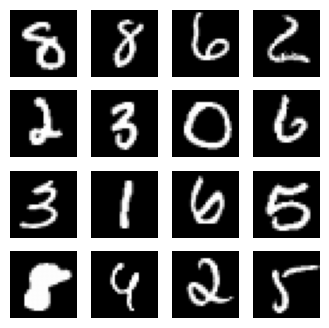

Shape ảnh gốc: torch.Size([128, 1, 28, 28])
Shape ảnh bị nhiễu: torch.Size([128, 1, 28, 28])
Shape noise: torch.Size([128, 1, 28, 28])


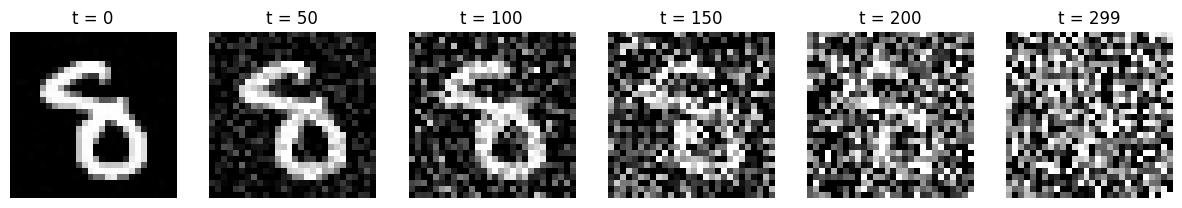

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Thiết bị đang dùng:", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x * 2.0 - 1.0)
])


dataset = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)


dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)


images, labels = next(iter(dataloader))

print("Shape của images:", images.shape)
print("Shape của labels:", labels.shape)
print("Giá trị nhỏ nhất:", images.min().item())
print("Giá trị lớn nhất:", images.max().item())


def show_tensor_images(images, num_images=16):
    images = images.detach().cpu()
    images = (images + 1) / 2
    images = images.clamp(0, 1)

    grid_size = int(num_images ** 0.5)

    plt.figure(figsize=(grid_size, grid_size))

    for i in range(num_images):
        plt.subplot(grid_size, grid_size, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.axis("off")

    plt.show()


show_tensor_images(images)


betas = torch.linspace(1e-4, 0.02, TIMESTEPS).to(device)

alphas = 1.0 - betas

alphas_cumprod = torch.cumprod(alphas, dim=0)

sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)

sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)


def get_index_from_list(values, timesteps, x_shape):
    batch_size = timesteps.shape[0]

    out = values.gather(-1, timesteps)

    out = out.reshape(batch_size, *((1,) * (len(x_shape) - 1)))

    return out.to(timesteps.device)


def forward_diffusion_sample(x_0, t):
    noise = torch.randn_like(x_0)

    sqrt_alpha_bar_t = get_index_from_list(
        sqrt_alphas_cumprod,
        t,
        x_0.shape
    )

    sqrt_one_minus_alpha_bar_t = get_index_from_list(
        sqrt_one_minus_alphas_cumprod,
        t,
        x_0.shape
    )

    x_t = sqrt_alpha_bar_t * x_0 + sqrt_one_minus_alpha_bar_t * noise

    return x_t, noise


images = images.to(device)

t = torch.randint(
    low=0,
    high=TIMESTEPS,
    size=(BATCH_SIZE,),
    device=device
).long()

x_t, noise = forward_diffusion_sample(images, t)

print("Shape ảnh gốc:", images.shape)
print("Shape ảnh bị nhiễu:", x_t.shape)
print("Shape noise:", noise.shape)


sample_image = images[0:1]

timesteps_to_show = [0, 50, 100, 150, 200, 299]

plt.figure(figsize=(15, 3))

for i, t_value in enumerate(timesteps_to_show):
    t = torch.tensor([t_value], device=device).long()

    noisy_image, _ = forward_diffusion_sample(sample_image, t)

    img = noisy_image.squeeze().detach().cpu()

    img = (img + 1) / 2

    img = img.clamp(0, 1)

    plt.subplot(1, len(timesteps_to_show), i + 1)

    plt.imshow(img, cmap="gray")

    plt.title(f"t = {t_value}")

    plt.axis("off")

plt.show()

In [ ]:
# MNIST DIFFUSION MODEL
import os
import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image

import matplotlib.pyplot as plt
from IPython.display import display, Image as IPythonImage

# 1. CONFIG
@dataclass
class DiffusionConfig:
    image_size: int = 32
    in_channels: int = 1

    base_channels: int = 32
    time_emb_dim: int = 256

    timesteps: int = 300
    beta_start: float = 1e-4
    beta_end: float = 0.02

    batch_size: int = 64
    epochs: int = 3
    learning_rate: float = 2e-4

    num_sample_images: int = 16
    max_batches_per_epoch: int = 300

    data_dir: str = "data"
    output_dir: str = "outputs"

    device: str = "cuda" if torch.cuda.is_available() else "cpu"


config = DiffusionConfig()

os.makedirs(config.output_dir, exist_ok=True)

print("Thiết bị đang dùng:", config.device)

Thiết bị đang dùng: cuda


In [ ]:
# 2. DATASET - MNIST
def get_mnist_dataloader(config):
    transform = transforms.Compose([
        transforms.Resize((config.image_size, config.image_size)),
        transforms.ToTensor(),
        transforms.Lambda(lambda x: x * 2.0 - 1.0),
    ])

    dataset = datasets.MNIST(
        root=config.data_dir,
        train=True,
        download=True,
        transform=transform,
    )

    dataloader = DataLoader(
        dataset,
        batch_size=config.batch_size,
        shuffle=True,
        drop_last=True,
    )

    return dataloader


dataloader = get_mnist_dataloader(config)

images, labels = next(iter(dataloader))

print("Shape images:", images.shape)
print("Shape labels:", labels.shape)
print("Pixel min:", images.min().item())
print("Pixel max:", images.max().item())

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 501kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.70MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.2MB/s]

Shape images: torch.Size([64, 1, 32, 32])
Shape labels: torch.Size([64])
Pixel min: -1.0
Pixel max: 1.0


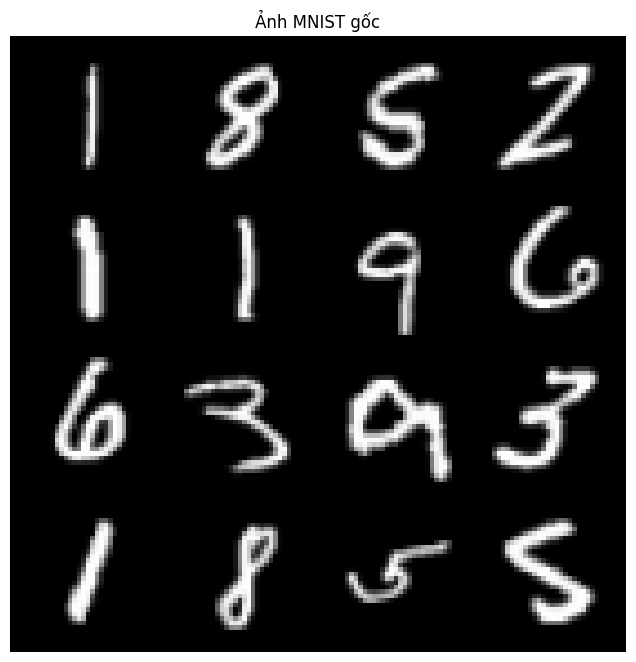

In [ ]:
# 3. UTILS - DISPLAY & SAVE IMAGE
def show_images(images, nrow=4, title=None):
    images = images.detach().cpu()

    if images.min() < 0:
        images = (images + 1) / 2

    images = images.clamp(0, 1)
    grid = make_grid(images, nrow=nrow)
    plt.figure(figsize=(8, 8))

    if grid.shape[0] == 1:
        plt.imshow(grid.squeeze(), cmap="gray")
    else:
        plt.imshow(grid.permute(1, 2, 0))
    if title is not None:
        plt.title(title)

    plt.axis("off")
    plt.show()

def save_minus1_to1_images(images, path, nrow=4):
    images = images.detach().cpu()
    images = images.clamp(-1, 1)
    images = (images + 1) / 2
    save_image(images, path, nrow=nrow)

show_images(images[:16], nrow=4, title="Ảnh MNIST gốc")

In [ ]:
# 4. TIME EMBEDDING
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(
            torch.arange(half_dim, device=device) * -embeddings
        )
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat(
            (embeddings.sin(), embeddings.cos()),
            dim=-1
        )

        return embeddings

In [ ]:
# 5. U-NET BLOCK
class Block(nn.Module):
    def __init__(self, in_ch, out_ch, time_emb_dim, up=False):
        super().__init__()

        self.time_mlp = nn.Linear(time_emb_dim, out_ch)

        if up:
            self.conv1 = nn.Conv2d(
                2 * in_ch,
                out_ch,
                kernel_size=3,
                padding=1,
            )

            self.transform = nn.ConvTranspose2d(
                out_ch,
                out_ch,
                kernel_size=4,
                stride=2,
                padding=1,
            )
        else:
            self.conv1 = nn.Conv2d(
                in_ch,
                out_ch,
                kernel_size=3,
                padding=1,
            )

            self.transform = nn.Conv2d(
                out_ch,
                out_ch,
                kernel_size=4,
                stride=2,
                padding=1,
            )

        self.conv2 = nn.Conv2d(
            out_ch,
            out_ch,
            kernel_size=3,
            padding=1,
        )

        self.norm1 = nn.GroupNorm(8, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)

        self.act = nn.GELU()

    def forward(self, x, t):
        h = self.conv1(x)
        h = self.act(h)
        h = self.norm1(h)

        time_emb = self.time_mlp(t)
        time_emb = self.act(time_emb)
        time_emb = time_emb[:, :, None, None]

        h = h + time_emb

        h = self.conv2(h)
        h = self.act(h)
        h = self.norm2(h)

        return self.transform(h)

In [ ]:
# 6. SIMPLE U-NET - MÔ HÌNH DỰ ĐOÁN NHIỄU
class SimpleUNet(nn.Module):
    def __init__(self, config):
        super().__init__()
        base = config.base_channels

        down_channels = (base,
            base * 2,
            base * 4,
            base * 8,
            base * 16,
        )

        up_channels = (
            base * 16,
            base * 8,
            base * 4,
            base * 2,
            base,
        )

        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(config.time_emb_dim),
            nn.Linear(config.time_emb_dim, config.time_emb_dim),
            nn.GELU(),
        )

        self.conv0 = nn.Conv2d(
            config.in_channels,
            down_channels[0],
            kernel_size=3,
            padding=1,
        )

        self.downs = nn.ModuleList([
            Block(
                down_channels[i],
                down_channels[i + 1],
                config.time_emb_dim,
                up=False,
            )
            for i in range(len(down_channels) - 1)
        ])

        self.ups = nn.ModuleList([
            Block(
                up_channels[i],
                up_channels[i + 1],
                config.time_emb_dim,
                up=True,
            )
            for i in range(len(up_channels) - 1)
        ])

        self.output = nn.Conv2d(
            up_channels[-1],
            config.in_channels,
            kernel_size=1,
        )

    def forward(self, x, timestep):
        t = self.time_mlp(timestep)
        x = self.conv0(x)
        residual_inputs = []

        for down in self.downs:
            x = down(x, t)
            residual_inputs.append(x)

        for up in self.ups:
            residual_x = residual_inputs.pop()
            x = torch.cat((x, residual_x), dim=1)
            x = up(x, t)

        return self.output(x)

In [ ]:
# 7. DIFFUSION CLASS
class Diffusion(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.config = config
        self.model = SimpleUNet(config)

        beta = torch.linspace(
            config.beta_start,
            config.beta_end,
            config.timesteps,
        )

        alpha = 1.0 - beta
        alpha_hat = torch.cumprod(alpha, dim=0)

        self.register_buffer("beta", beta)
        self.register_buffer("alpha", alpha)
        self.register_buffer("alpha_hat", alpha_hat)

    def noise_images(self, x, t):
        sqrt_alpha_hat = torch.sqrt(
            self.alpha_hat[t]
        )[:, None, None, None]

        sqrt_one_minus_alpha_hat = torch.sqrt(
            1.0 - self.alpha_hat[t]
        )[:, None, None, None]

        noise = torch.randn_like(x)

        x_t = sqrt_alpha_hat * x + sqrt_one_minus_alpha_hat * noise

        return x_t, noise

    def sample_timesteps(self, n):
        return torch.randint(
            low=1,
            high=self.config.timesteps,
            size=(n,),
            device=self.alpha_hat.device,
        ).long()

    def forward(self, x):
        t = self.sample_timesteps(x.shape[0])

        x_t, noise = self.noise_images(x, t)

        predicted_noise = self.model(x_t, t)

        loss = F.mse_loss(noise, predicted_noise)

        return loss

    @torch.no_grad()
    def sample(self, n_samples):
        self.model.eval()

        x = torch.randn(
            (
                n_samples,
                self.config.in_channels,
                self.config.image_size,
                self.config.image_size,
            ),
            device=self.alpha_hat.device,
        )

        for i in reversed(range(1, self.config.timesteps)):
            t = torch.full(
                (n_samples,),
                i,
                device=self.alpha_hat.device,
                dtype=torch.long,
            )

            predicted_noise = self.model(x, t)

            alpha = self.alpha[t][:, None, None, None]
            alpha_hat = self.alpha_hat[t][:, None, None, None]
            beta = self.beta[t][:, None, None, None]

            if i > 1:
                noise = torch.randn_like(x)
            else:
                noise = torch.zeros_like(x)

            x = (
                1 / torch.sqrt(alpha)
            ) * (
                x
                - ((1 - alpha) / torch.sqrt(1 - alpha_hat))
                * predicted_noise
            ) + torch.sqrt(beta) * noise

        self.model.train()

        x = x.clamp(-1, 1)
        x = (x + 1) / 2

        return x

In [ ]:
# 8. CREATE MODEL VÀ TEST SHAPE
diffusion = Diffusion(config).to(config.device)

test_images = images[:config.batch_size].to(config.device)

test_t = diffusion.sample_timesteps(test_images.shape[0])

test_x_t, test_noise = diffusion.noise_images(test_images, test_t)

test_pred_noise = diffusion.model(test_x_t, test_t)

print("Shape ảnh gốc:", test_images.shape)
print("Shape ảnh nhiễu:", test_x_t.shape)
print("Shape noise thật:", test_noise.shape)
print("Shape noise dự đoán:", test_pred_noise.shape)

Shape ảnh gốc: torch.Size([64, 1, 32, 32])
Shape ảnh nhiễu: torch.Size([64, 1, 32, 32])
Shape noise thật: torch.Size([64, 1, 32, 32])
Shape noise dự đoán: torch.Size([64, 1, 32, 32])


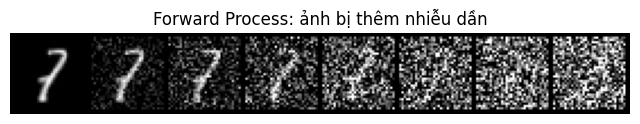

Đã lưu ảnh forward process tại: outputs/forward_process_demo.png


In [ ]:
# 9. SHOW FORWARD PROCESS
@torch.no_grad()
def show_forward_process(diffusion, dataloader, config):
    images, _ = next(iter(dataloader))

    image = images[0:1].to(config.device)

    timesteps_to_show = torch.linspace(
        0,
        config.timesteps - 1,
        steps=8,
        device=config.device,
    ).long()

    noisy_images = []

    for t_value in timesteps_to_show:
        t = torch.tensor([t_value], device=config.device).long()

        noisy_image, _ = diffusion.noise_images(image, t)

        noisy_images.append(noisy_image)

    noisy_images = torch.cat(noisy_images, dim=0)

    save_path = os.path.join(
        config.output_dir,
        "forward_process_demo.png",
    )

    save_minus1_to1_images(noisy_images, save_path, nrow=8)

    show_images(
        noisy_images,
        nrow=8,
        title="Forward Process: ảnh bị thêm nhiễu dần",
    )

    print("Đã lưu ảnh forward process tại:", save_path)


show_forward_process(diffusion, dataloader, config)

Epoch [1/20] Batch [0] Loss: 1.0474
Epoch [1/20] Batch [50] Loss: 0.2292
Epoch [1/20] Batch [100] Loss: 0.1473
Epoch [1/20] Batch [150] Loss: 0.1073
Epoch [1/20] Batch [200] Loss: 0.0773
Epoch [1/20] Batch [250] Loss: 0.0774

Epoch [1/20] Average Loss: 0.1711


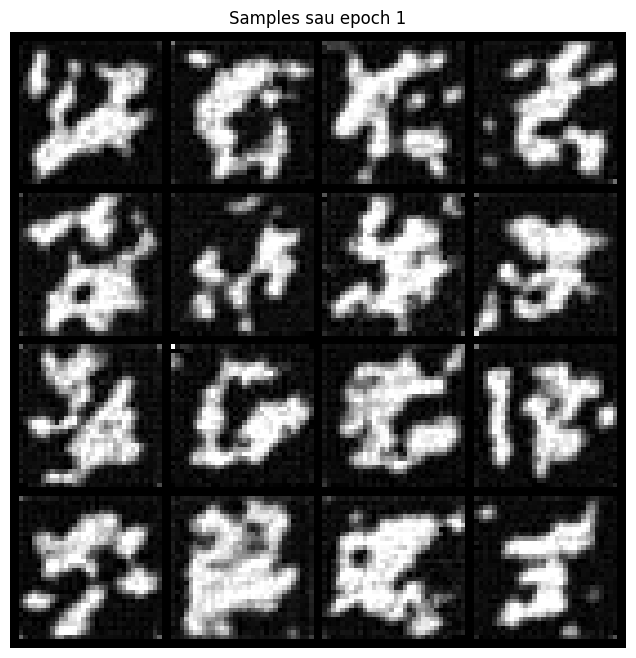

Đã lưu ảnh mẫu tại: outputs/samples_epoch_001.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [2/20] Batch [0] Loss: 0.0603
Epoch [2/20] Batch [50] Loss: 0.0677
Epoch [2/20] Batch [100] Loss: 0.0572
Epoch [2/20] Batch [150] Loss: 0.0625
Epoch [2/20] Batch [200] Loss: 0.0571
Epoch [2/20] Batch [250] Loss: 0.0601

Epoch [2/20] Average Loss: 0.0635


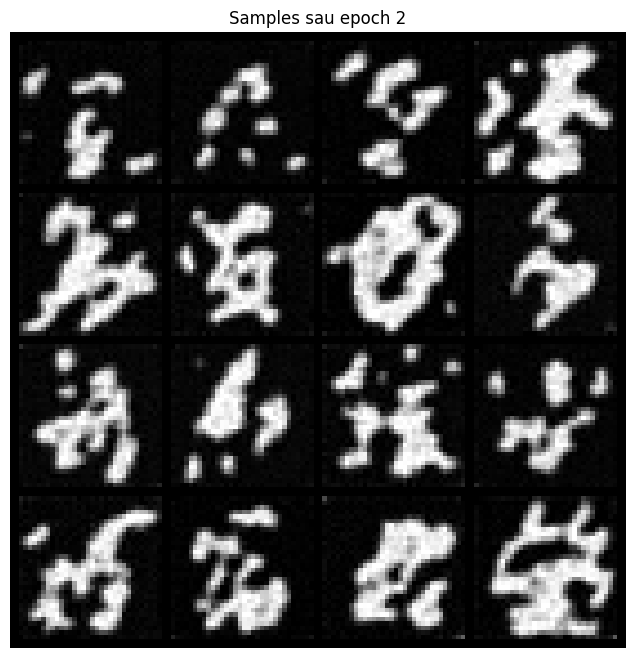

Đã lưu ảnh mẫu tại: outputs/samples_epoch_002.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [3/20] Batch [0] Loss: 0.0552
Epoch [3/20] Batch [50] Loss: 0.0585
Epoch [3/20] Batch [100] Loss: 0.0608
Epoch [3/20] Batch [150] Loss: 0.0540
Epoch [3/20] Batch [200] Loss: 0.0468
Epoch [3/20] Batch [250] Loss: 0.0572

Epoch [3/20] Average Loss: 0.0557


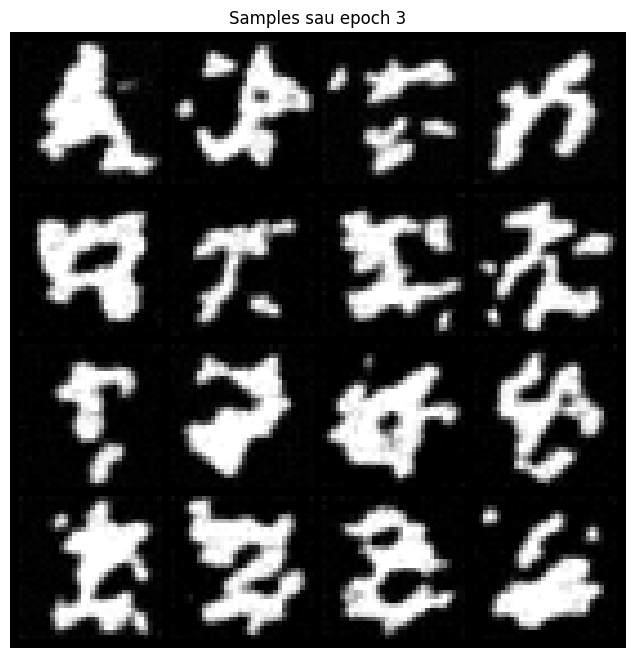

Đã lưu ảnh mẫu tại: outputs/samples_epoch_003.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [4/20] Batch [0] Loss: 0.0524
Epoch [4/20] Batch [50] Loss: 0.0501
Epoch [4/20] Batch [100] Loss: 0.0573
Epoch [4/20] Batch [150] Loss: 0.0482
Epoch [4/20] Batch [200] Loss: 0.0564
Epoch [4/20] Batch [250] Loss: 0.0563

Epoch [4/20] Average Loss: 0.0518


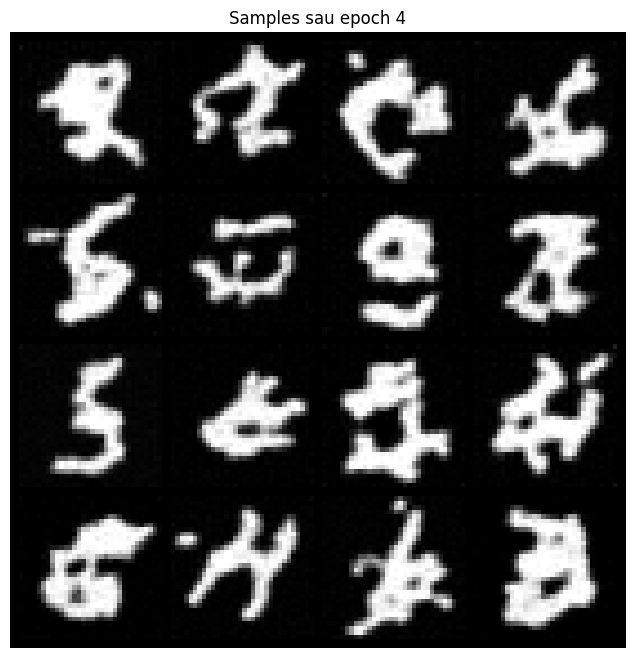

Đã lưu ảnh mẫu tại: outputs/samples_epoch_004.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [5/20] Batch [0] Loss: 0.0427
Epoch [5/20] Batch [50] Loss: 0.0544
Epoch [5/20] Batch [100] Loss: 0.0502
Epoch [5/20] Batch [150] Loss: 0.0508
Epoch [5/20] Batch [200] Loss: 0.0465
Epoch [5/20] Batch [250] Loss: 0.0511

Epoch [5/20] Average Loss: 0.0482


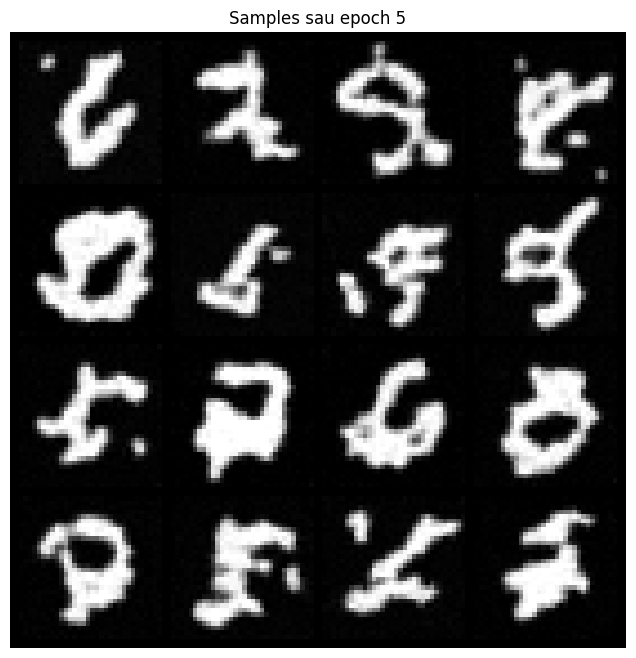

Đã lưu ảnh mẫu tại: outputs/samples_epoch_005.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [6/20] Batch [0] Loss: 0.0508
Epoch [6/20] Batch [50] Loss: 0.0535
Epoch [6/20] Batch [100] Loss: 0.0491
Epoch [6/20] Batch [150] Loss: 0.0427
Epoch [6/20] Batch [200] Loss: 0.0484
Epoch [6/20] Batch [250] Loss: 0.0505

Epoch [6/20] Average Loss: 0.0447


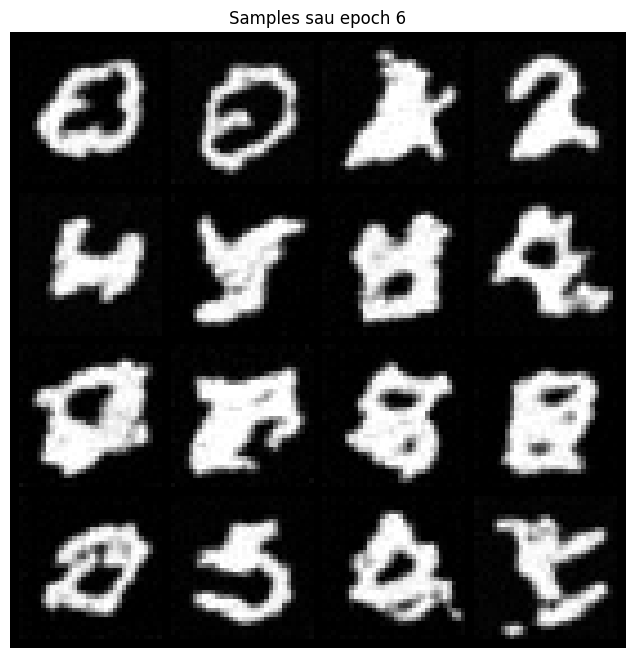

Đã lưu ảnh mẫu tại: outputs/samples_epoch_006.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [7/20] Batch [0] Loss: 0.0592
Epoch [7/20] Batch [50] Loss: 0.0487
Epoch [7/20] Batch [100] Loss: 0.0454
Epoch [7/20] Batch [150] Loss: 0.0403
Epoch [7/20] Batch [200] Loss: 0.0343
Epoch [7/20] Batch [250] Loss: 0.0384

Epoch [7/20] Average Loss: 0.0432


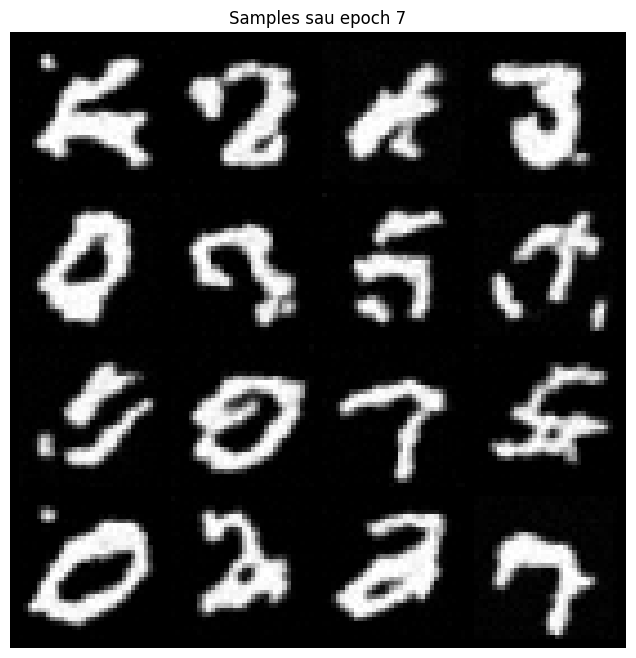

Đã lưu ảnh mẫu tại: outputs/samples_epoch_007.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [8/20] Batch [0] Loss: 0.0406
Epoch [8/20] Batch [50] Loss: 0.0414
Epoch [8/20] Batch [100] Loss: 0.0472
Epoch [8/20] Batch [150] Loss: 0.0341
Epoch [8/20] Batch [200] Loss: 0.0473
Epoch [8/20] Batch [250] Loss: 0.0497

Epoch [8/20] Average Loss: 0.0418


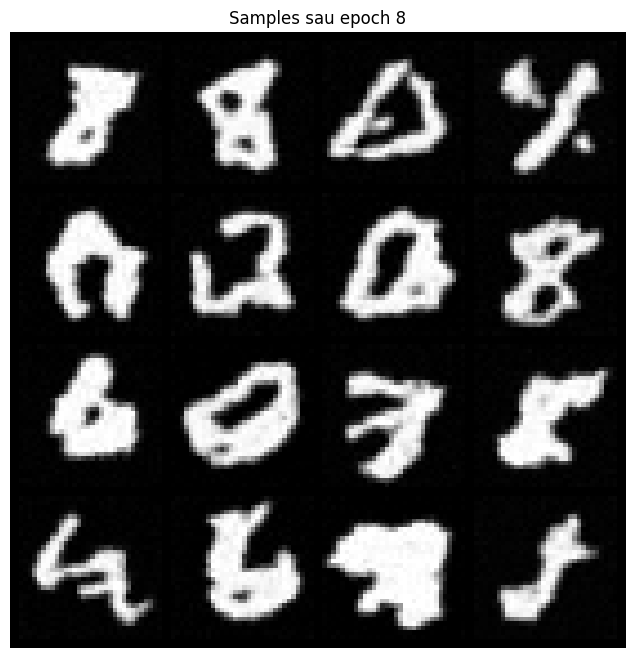

Đã lưu ảnh mẫu tại: outputs/samples_epoch_008.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [9/20] Batch [0] Loss: 0.0460
Epoch [9/20] Batch [50] Loss: 0.0351
Epoch [9/20] Batch [100] Loss: 0.0432
Epoch [9/20] Batch [150] Loss: 0.0346
Epoch [9/20] Batch [200] Loss: 0.0407
Epoch [9/20] Batch [250] Loss: 0.0412

Epoch [9/20] Average Loss: 0.0403


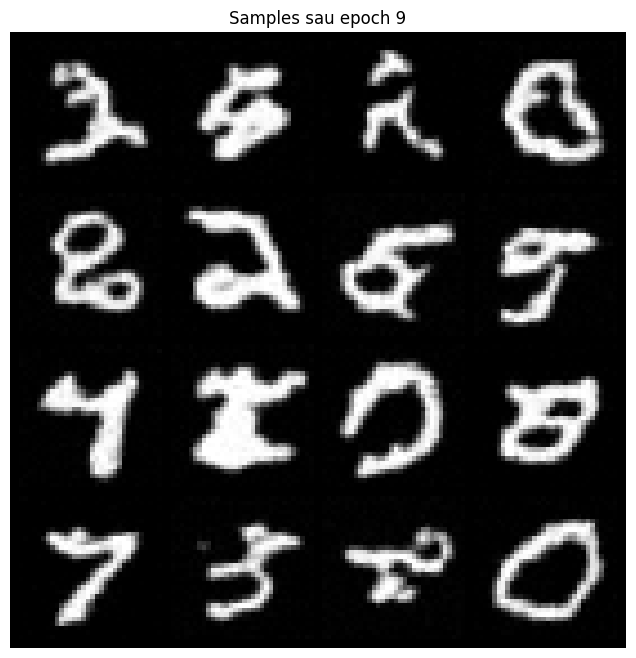

Đã lưu ảnh mẫu tại: outputs/samples_epoch_009.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [10/20] Batch [0] Loss: 0.0411
Epoch [10/20] Batch [50] Loss: 0.0372
Epoch [10/20] Batch [100] Loss: 0.0463
Epoch [10/20] Batch [150] Loss: 0.0393
Epoch [10/20] Batch [200] Loss: 0.0428
Epoch [10/20] Batch [250] Loss: 0.0432

Epoch [10/20] Average Loss: 0.0399


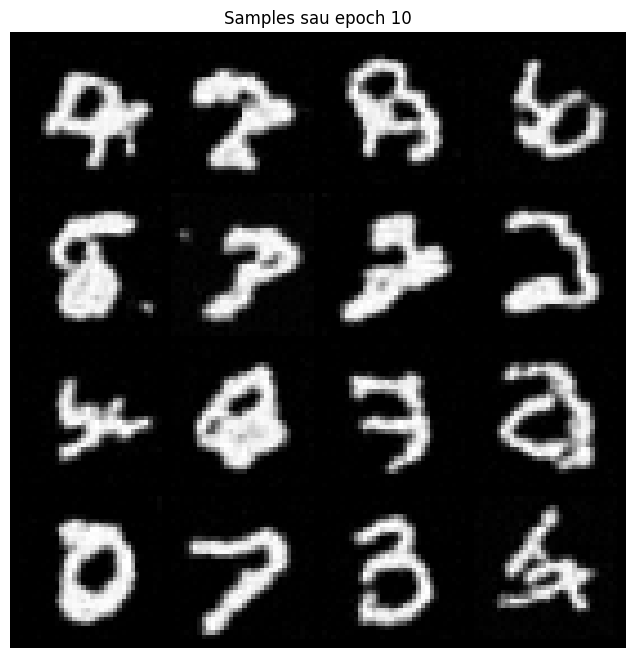

Đã lưu ảnh mẫu tại: outputs/samples_epoch_010.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [11/20] Batch [0] Loss: 0.0503
Epoch [11/20] Batch [50] Loss: 0.0356
Epoch [11/20] Batch [100] Loss: 0.0410
Epoch [11/20] Batch [150] Loss: 0.0362
Epoch [11/20] Batch [200] Loss: 0.0475
Epoch [11/20] Batch [250] Loss: 0.0395

Epoch [11/20] Average Loss: 0.0392


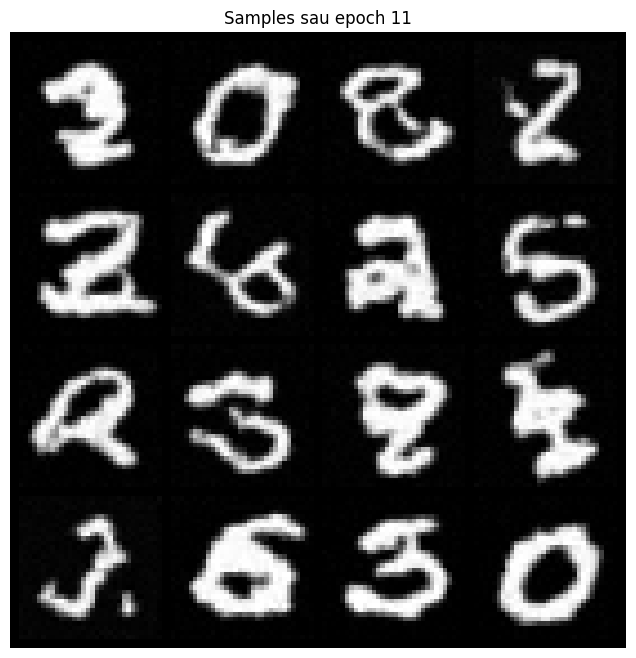

Đã lưu ảnh mẫu tại: outputs/samples_epoch_011.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [12/20] Batch [0] Loss: 0.0279
Epoch [12/20] Batch [50] Loss: 0.0502
Epoch [12/20] Batch [100] Loss: 0.0450
Epoch [12/20] Batch [150] Loss: 0.0432
Epoch [12/20] Batch [200] Loss: 0.0303
Epoch [12/20] Batch [250] Loss: 0.0370

Epoch [12/20] Average Loss: 0.0396


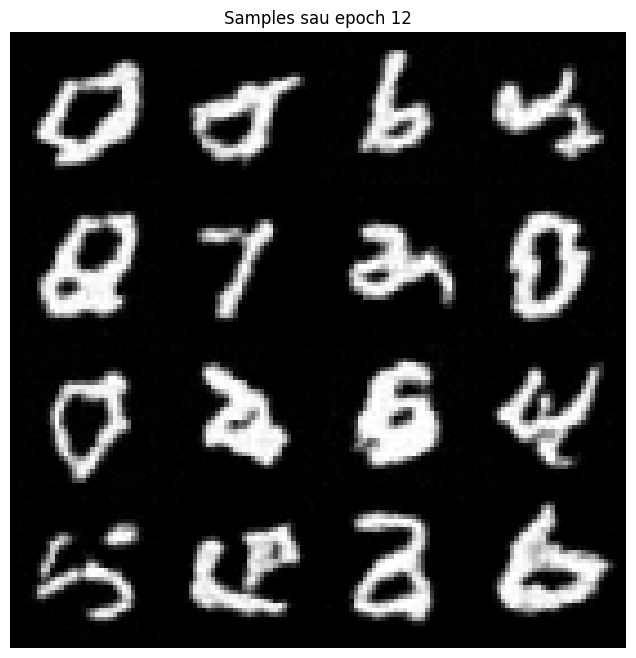

Đã lưu ảnh mẫu tại: outputs/samples_epoch_012.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [13/20] Batch [0] Loss: 0.0363
Epoch [13/20] Batch [50] Loss: 0.0437
Epoch [13/20] Batch [100] Loss: 0.0421
Epoch [13/20] Batch [150] Loss: 0.0353
Epoch [13/20] Batch [200] Loss: 0.0480
Epoch [13/20] Batch [250] Loss: 0.0324

Epoch [13/20] Average Loss: 0.0387


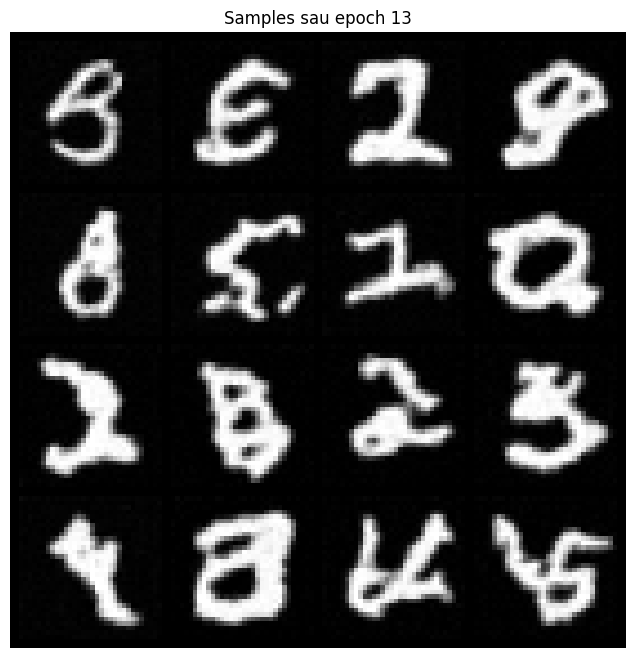

Đã lưu ảnh mẫu tại: outputs/samples_epoch_013.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [14/20] Batch [0] Loss: 0.0412
Epoch [14/20] Batch [50] Loss: 0.0448
Epoch [14/20] Batch [100] Loss: 0.0378
Epoch [14/20] Batch [150] Loss: 0.0435
Epoch [14/20] Batch [200] Loss: 0.0449
Epoch [14/20] Batch [250] Loss: 0.0337

Epoch [14/20] Average Loss: 0.0381


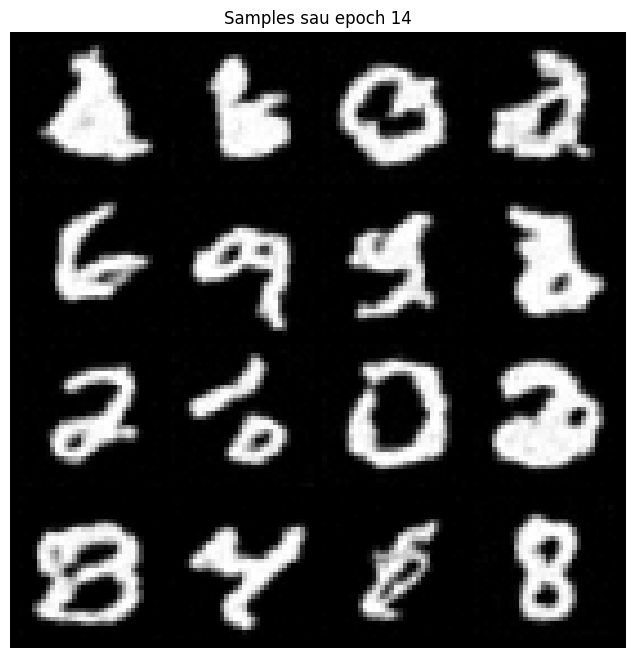

Đã lưu ảnh mẫu tại: outputs/samples_epoch_014.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [15/20] Batch [0] Loss: 0.0331
Epoch [15/20] Batch [50] Loss: 0.0290
Epoch [15/20] Batch [100] Loss: 0.0377
Epoch [15/20] Batch [150] Loss: 0.0388
Epoch [15/20] Batch [200] Loss: 0.0385
Epoch [15/20] Batch [250] Loss: 0.0476

Epoch [15/20] Average Loss: 0.0370


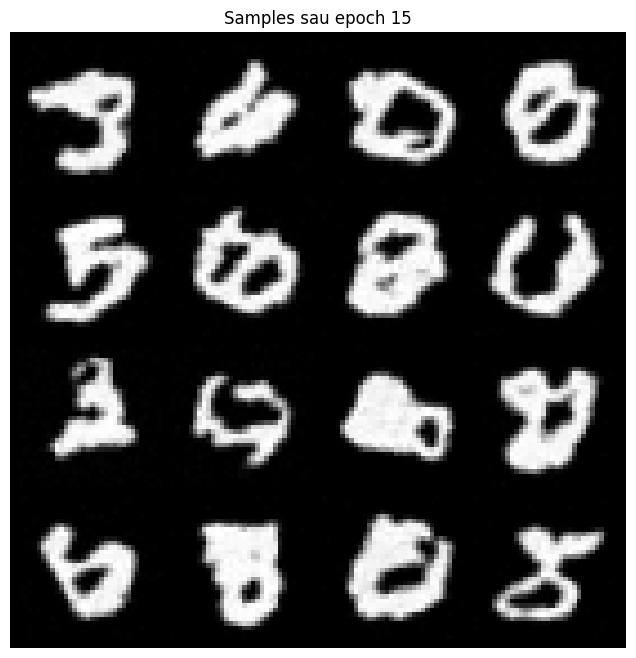

Đã lưu ảnh mẫu tại: outputs/samples_epoch_015.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [16/20] Batch [0] Loss: 0.0317
Epoch [16/20] Batch [50] Loss: 0.0335
Epoch [16/20] Batch [100] Loss: 0.0369
Epoch [16/20] Batch [150] Loss: 0.0343
Epoch [16/20] Batch [200] Loss: 0.0377
Epoch [16/20] Batch [250] Loss: 0.0383

Epoch [16/20] Average Loss: 0.0370


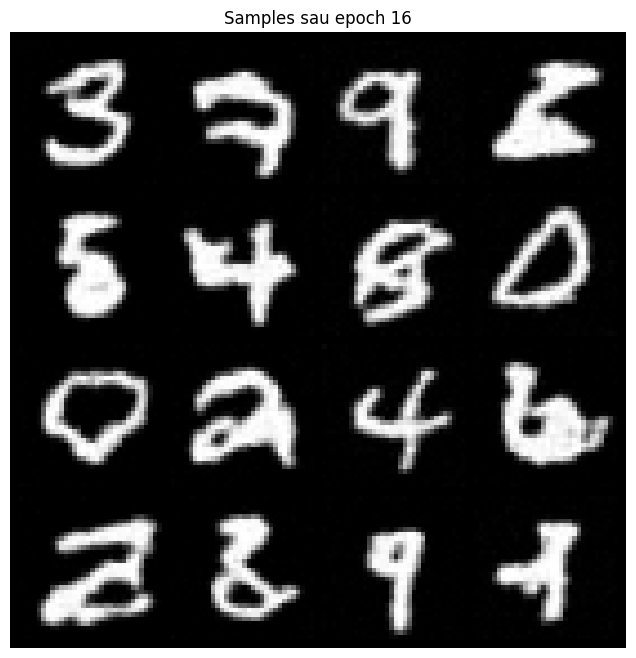

Đã lưu ảnh mẫu tại: outputs/samples_epoch_016.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [17/20] Batch [0] Loss: 0.0301
Epoch [17/20] Batch [50] Loss: 0.0369
Epoch [17/20] Batch [100] Loss: 0.0288
Epoch [17/20] Batch [150] Loss: 0.0393
Epoch [17/20] Batch [200] Loss: 0.0376
Epoch [17/20] Batch [250] Loss: 0.0418

Epoch [17/20] Average Loss: 0.0365


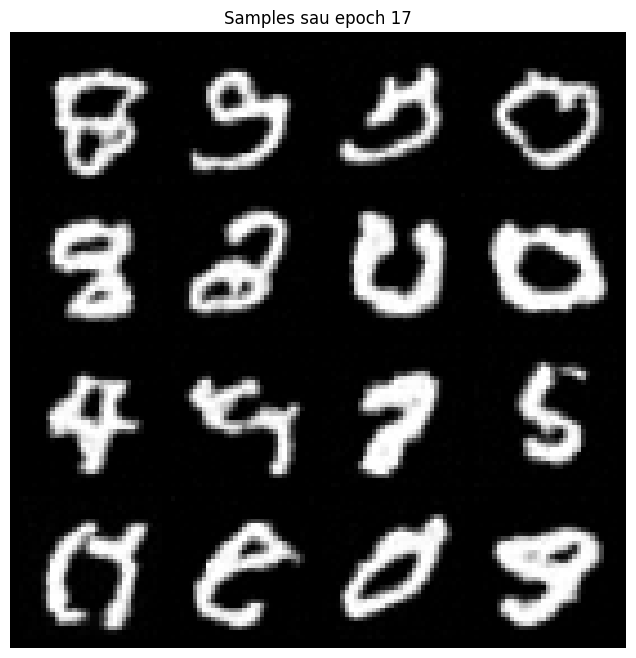

Đã lưu ảnh mẫu tại: outputs/samples_epoch_017.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [18/20] Batch [0] Loss: 0.0417
Epoch [18/20] Batch [50] Loss: 0.0391
Epoch [18/20] Batch [100] Loss: 0.0327
Epoch [18/20] Batch [150] Loss: 0.0440
Epoch [18/20] Batch [200] Loss: 0.0477
Epoch [18/20] Batch [250] Loss: 0.0364

Epoch [18/20] Average Loss: 0.0363


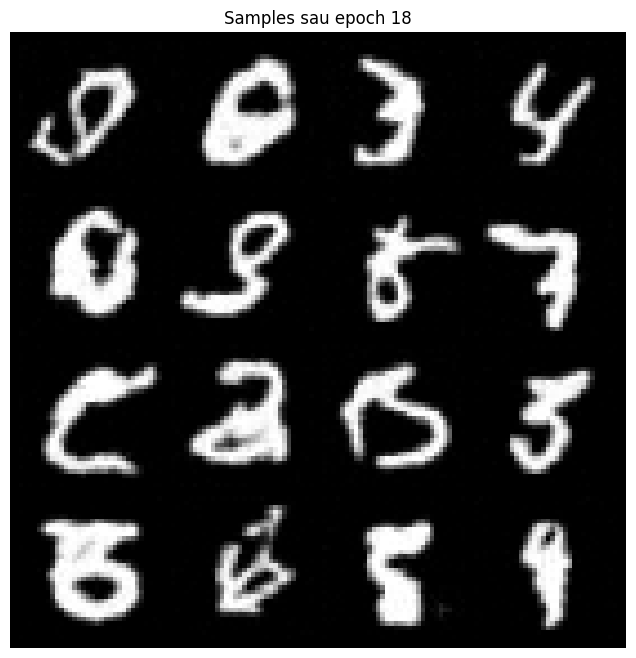

Đã lưu ảnh mẫu tại: outputs/samples_epoch_018.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [19/20] Batch [0] Loss: 0.0413
Epoch [19/20] Batch [50] Loss: 0.0373
Epoch [19/20] Batch [100] Loss: 0.0342
Epoch [19/20] Batch [150] Loss: 0.0394
Epoch [19/20] Batch [200] Loss: 0.0304
Epoch [19/20] Batch [250] Loss: 0.0347

Epoch [19/20] Average Loss: 0.0355


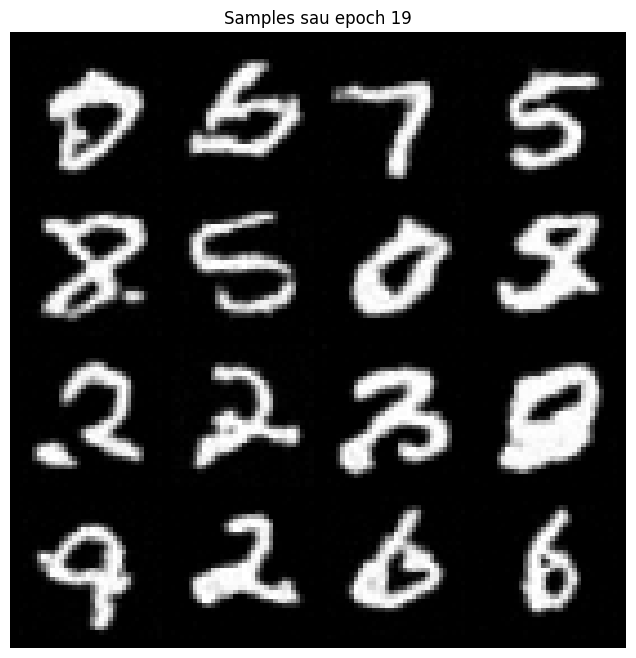

Đã lưu ảnh mẫu tại: outputs/samples_epoch_019.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------
Epoch [20/20] Batch [0] Loss: 0.0312
Epoch [20/20] Batch [50] Loss: 0.0299
Epoch [20/20] Batch [100] Loss: 0.0362
Epoch [20/20] Batch [150] Loss: 0.0431
Epoch [20/20] Batch [200] Loss: 0.0480
Epoch [20/20] Batch [250] Loss: 0.0306

Epoch [20/20] Average Loss: 0.0351


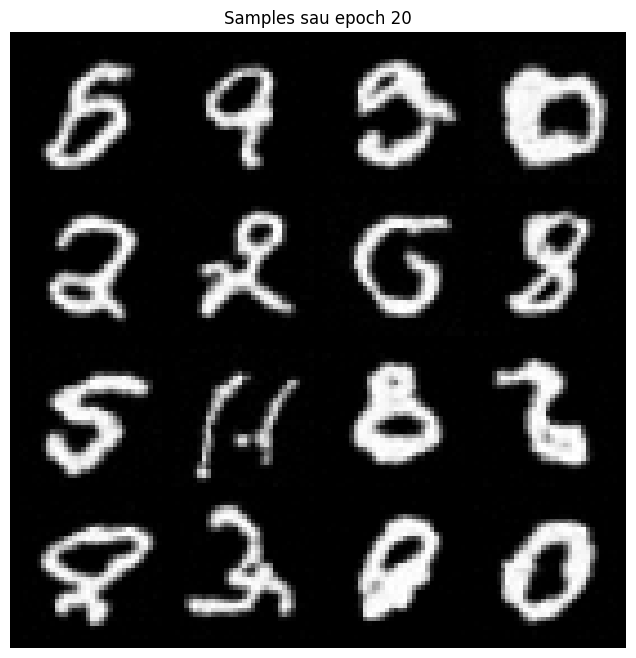

Đã lưu ảnh mẫu tại: outputs/samples_epoch_020.png
Đã lưu checkpoint tại: outputs/mnist_diffusion_checkpoint.pt
------------------------------------------------------------


In [ ]:
# 10. TRAINING LOOP
optimizer = torch.optim.AdamW(
    diffusion.parameters(),
    lr=config.learning_rate,
)

def train(diffusion, dataloader, optimizer, config):
    diffusion.train()

    for epoch in range(config.epochs):
        total_loss = 0.0

        for batch_idx, (images, _) in enumerate(dataloader):
            if config.max_batches_per_epoch > 0:
                if batch_idx >= config.max_batches_per_epoch:
                    break

            images = images.to(config.device)

            loss = diffusion(images)

            optimizer.zero_grad(set_to_none=True)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

            if batch_idx % 50 == 0:
                print(
                    f"Epoch [{epoch + 1}/{config.epochs}] "
                    f"Batch [{batch_idx}] "
                    f"Loss: {loss.item():.4f}"
                )

        num_batches = batch_idx + 1
        avg_loss = total_loss / num_batches

        print(
            f"\nEpoch [{epoch + 1}/{config.epochs}] "
            f"Average Loss: {avg_loss:.4f}"
        )

        samples = diffusion.sample(config.num_sample_images)

        sample_path = os.path.join(
            config.output_dir,
            f"samples_epoch_{epoch + 1:03d}.png",
        )

        save_image(samples, sample_path, nrow=4)

        show_images(
            samples,
            nrow=4,
            title=f"Samples sau epoch {epoch + 1}",
        )

        checkpoint_path = os.path.join(
            config.output_dir,
            "mnist_diffusion_checkpoint.pt",
        )

        torch.save(
            {
                "epoch": epoch + 1,
                "config": config.__dict__,
                "model_state_dict": diffusion.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "loss": avg_loss,
            },
            checkpoint_path,
        )

        print("Đã lưu ảnh mẫu tại:", sample_path)
        print("Đã lưu checkpoint tại:", checkpoint_path)
        print("-" * 60)


train(diffusion, dataloader, optimizer, config)

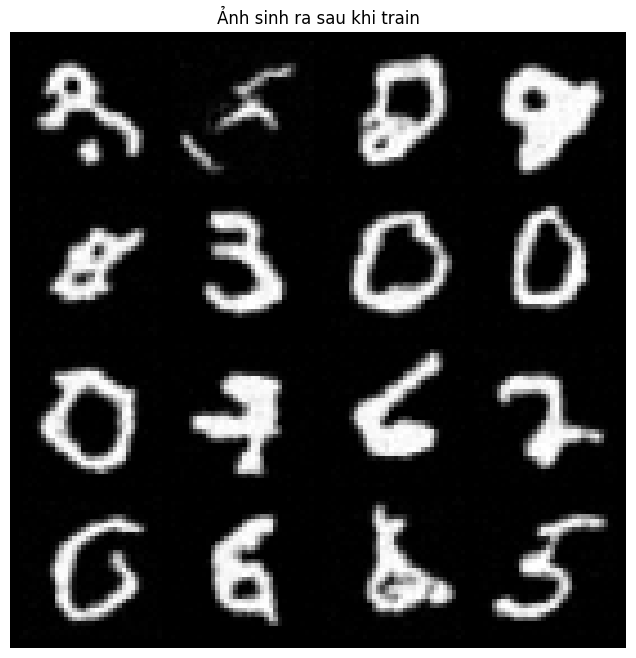

Đã lưu ảnh cuối tại: outputs/final_samples.png


In [ ]:
# 11. GEN IMAGE AFFTER TRAINING
samples = diffusion.sample(16)

show_images(
    samples,
    nrow=4,
    title="Ảnh sinh ra sau khi train",
)

final_sample_path = os.path.join(
    config.output_dir,
    "final_samples.png",
)

save_image(samples, final_sample_path, nrow=4)

print("Đã lưu ảnh cuối tại:", final_sample_path)